Dataset:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

Dataset Shape: (999, 9)

--- Logistic Regression ---
Accuracy: 0.92

Confusion Matrix:
[[184   0]
 [ 16   0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96       184
           1       0.00      0.0

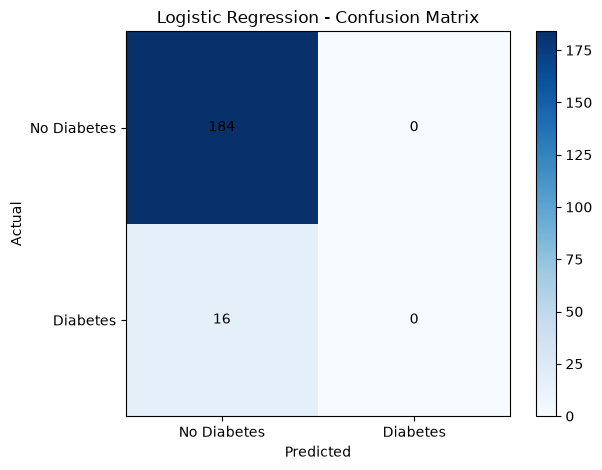

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


df = pd.read_csv(
    r"C:\Users\harsh\OneDrive\Desktop\NIE\DAV\diabetes_prediction_dataset.csv"
)

print("Dataset:")
print(df.head())
print("\nDataset Shape:", df.shape)


X = df[["age", "heart_disease", "hypertension"]]
y = df["diabetes"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\n--- Logistic Regression ---")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

new_sample = pd.DataFrame({
    "age": [30],
    "heart_disease": [0],
    "hypertension": [0]
})

prediction = model.predict(new_sample)[0]
probability = model.predict_proba(new_sample)[0][1]

print("\nPredicted Diabetes:", int(prediction))
print("Predicted Diabetes Probability:", round(probability * 100, 2), "%")

cm = confusion_matrix(y_test, y_pred)

plt.imshow(cm, cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
plt.yticks([0, 1], ["No Diabetes", "Diabetes"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()
